# Passaggio 4: spread e segnale, coppia MA-V (Mastercard - Visa)

**Obiettivo.** Costruire lo spread tra MA e V, misurare quanto è lontano dal suo valore normale (z-score con EMA) e trasformare questa misura in **segnali di ingresso e uscita**. È la parte matematica della strategia, indipendente dall'agente di notizie (Passaggio 5).

**Perché solo una coppia e solo il train.** Prima di scalare alle 10 coppie vogliamo capire se la pipeline funziona e quante occasioni di trade ci sono. Il periodo (96 giorni, 16 giugno - 30 ottobre 2026) è diviso in ordine cronologico: **i primi 64 giorni sono il train** (16 giugno - 16 settembre), **gli ultimi 32 sono il test** (17 settembre - 30 ottobre). Questo notebook usa **solo il train**: il test non viene mai calcolato né guardato, e verrà usato una volta sola, alla fine, con i parametri già bloccati.

**Come leggerlo.** Ogni sezione ha una spiegazione in italiano semplice di *cosa* si fa e *perché*, poi il codice, poi una **Lettura** che commenta il risultato. Le scelte che sono nostre decisioni (e non del programma) sono segnate con **[SCELTA]**; quelle ancora aperte con **[APERTO]**.

| Parte | Cosa fa | Perché |
|---|---|---|
| 1 | Parametri | tutte le scelte in un posto solo, con la motivazione |
| 2 | Caricamento e divisione train / test | il test resta intoccato |
| 3 | Lo spread: logaritmico con β = 1, confronto con la regressione (OLS) | le due gambe hanno lo stesso importo |
| 4 | Lo z-score: EMA continua (scelta) e con azzeramento giornaliero (confronto) | misura quanto lo spread è anomalo |
| 5 | Le regole di ingresso e uscita | trasformano lo z-score in trade |
| 6 | Prova dei parametri sul train e scelta | scegliere senza "inseguire" il caso |
| 7 | I segnali con i parametri scelti: diagnostica | capire *quando* e *perché* funzionano |
| 8 | Confronto con l'EMA azzerata ogni giorno | l'alternativa richiesta |
| 9 | Salvataggio dei segnali del train | input del Passaggio 5 |
| 10 | Cosa abbiamo trovato, limiti, cosa resta aperto | |

## 1. Parametri

Tutte le scelte stanno qui. Quelle col commento **[SCELTA]** sono decisioni nostre: si possono cambiare, ma vanno poi rilanciate le sezioni successive e riportate nel report.

In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller, coint

PAIR = "MA-V"
A, B = "MA UN Equity", "V UN Equity"                              # A = primo titolo della coppia, B = secondo
PAIRS_DIR = Path("../data/processed/pairs_intraday")             # file puliti del Passaggio 2
OUT_SIGNALS = Path("../data/processed/signals_MA-V_train.csv")   # segnali del train, input del Passaggio 5 (cartella ignorata da git)

# --- Divisione train / test ---
N_TRAIN_DAYS = 64      # [SCELTA] circa due terzi di 96 giorni (proposta del programma). Ordine cronologico, mai casuale.

# --- Dati ---
N_MINUTES = 390        # barre da 1 minuto per giornata: 09:30-15:59

# --- Z-score ---
EMA_MIN_PERIODS = 60   # [SCELTA] servono almeno 60 barre di storia prima di fidarsi di media e deviazione standard della EMA

# --- Regole di ingresso e uscita ---
OPEN_SKIP = 15         # [SCELTA] niente nuovi ingressi nei primi 15 minuti della seduta (aperture molto rumorose, spread bid-ask larghi)
CLOSE_SKIP = 30        # [SCELTA] niente nuovi ingressi negli ultimi 30 minuti: non resta il tempo per il rientro
MAX_HOLD = 90          # [SCELTA] tempo massimo di permanenza: 90 minuti (poi si esce)
STOP_EXTRA = 1.5       # [SCELTA] stop-loss: si esce se lo z-score peggiora di altri 1.5 oltre la soglia di ingresso
LOOKBACK = 30          # minuti usati solo per descrivere "quale titolo si è mosso di più" (colonna informativa per il Passaggio 5)

# --- Griglia di parametri provati sul train ---
GRID_HL = [30, 60, 120, 240]        # emivita della EMA, in barre da 1 minuto (cioè in minuti di seduta)
GRID_ENTRY = [1.5, 2.0, 2.5, 3.0]   # soglia di ingresso, in unità di z
GRID_EXIT = [0.0, 0.5]              # soglia di uscita: si esce quando z torna entro questo valore
MIN_TRADES = 30                     # [SCELTA] regola di scelta: servono almeno 30 trade nel train, sotto questa soglia il guadagno medio è solo rumore

## 2. Caricamento e divisione train / test

Si legge il file pulito a 1 minuto di MA-V creato nel Passaggio 2 (`MA-V_1min.parquet`): una riga per titolo e per minuto, con la colonna `filled` che dice se la barra è **riempita** (nessuno scambio in quel minuto, il prezzo è l'ultimo noto).

Il taglio è sul **giorno**, mai nel mezzo di una giornata: un trade chiuso a fine giornata non deve attraversare il confine.

In [2]:
raw = duckdb.sql(f"SELECT * FROM '{(PAIRS_DIR / f'{PAIR}_1min.parquet').as_posix()}'").df()
wide = lambda col: raw.pivot(index="ts", columns="ticker", values=col).sort_index()
close, open_, filled = wide("close"), wide("open"), wide("filled")

ts = close.index
day = ts.normalize()
days = sorted(set(day))
assert close.isna().sum().sum() == 0 and (pd.Series(day).value_counts() == N_MINUTES).all(), "ogni giorno deve avere 390 barre complete"

cut_day = days[N_TRAIN_DAYS - 1]
is_train = np.asarray(day <= cut_day)

print(f"{len(days)} giorni: {days[0].date()} - {days[-1].date()}")
print(f"train: {N_TRAIN_DAYS} giorni, {days[0].date()} - {cut_day.date()}  ({is_train.sum():,} barre)")
print(f"test : {len(days) - N_TRAIN_DAYS} giorni, {days[N_TRAIN_DAYS].date()} - {days[-1].date()}  ({(~is_train).sum():,} barre): NON viene usato in questo notebook")
print(f"quota di minuti riempiti, solo train:  MA {filled[A][is_train].mean():.1%}   V {filled[B][is_train].mean():.1%}")

96 giorni: 2026-06-16 - 2026-10-30
train: 64 giorni, 2026-06-16 - 2026-09-16  (24,960 barre)
test : 32 giorni, 2026-09-17 - 2026-10-30  (12,480 barre): NON viene usato in questo notebook
quota di minuti riempiti, solo train:  MA 9.5%   V 1.5%


**Lettura.** MA scambia poco in alcuni minuti (circa il 9% di barre riempite), V quasi mai (circa 1%). Il 10% circa dei minuti ha quindi almeno una gamba con prezzo "vecchio": ne teniamo conto nella regola degli ingressi (parte 5).

Per ricordarsi che il test non si tocca, **da qui in avanti ogni conteggio di trade e ogni risultato è calcolato solo sul train** (`is_train`). Gli z-score vengono calcolati sull'intera serie perché la EMA è *causale* (il valore di una barra usa solo barre passate, lo verifichiamo nella parte 4); i segnali però vengono generati solo nel train.

## 3. Lo spread

Il programma scrive lo spread come $S_t = P^A_t - \beta P^B_t$. Qui bisogna scegliere **in che unità** misurarlo e **quanto vale β**.

**[SCELTA] Spread in logaritmi con β = 1:**

$$S_t = \ln P^{MA}_t - \ln P^{V}_t$$

Perché:
- Abbiamo deciso di investire **lo stesso importo sulle due gambe, senza leva** (`Programma.md`, passaggio 1). Con importo uguale, il guadagno della coppia è, per piccoli movimenti, la differenza dei due rendimenti: $r_{MA} - r_V$. La differenza dei logaritmi dei prezzi misura esattamente questo. Con β = 1 lo spread **è** il guadagno della posizione.
- Un β diverso da 1 vorrebbe dire importi diversi sulle due gambe, in contrasto con la decisione presa.
- Lo spread in dollari ($P^{MA} - \beta P^{V}$) dipende dal livello assoluto dei prezzi (MA costa circa 490 $, V circa 325 $): in logaritmi i due titoli sono confrontabili.

**Confronto richiesto: β stimato con la regressione (OLS).** Si stima β con una regressione di $\ln P^{MA}$ su $\ln P^{V}$ **solo sui dati del train**. Se β fosse molto diverso da 1 e lo spread con β stimato fosse molto più stazionario (cioè tornasse davvero verso una media), varrebbe la pena rivedere la scelta.

In [3]:
logA, logB = np.log(close[A]), np.log(close[B])
S = logA - logB                                        # [SCELTA] spread logaritmico con beta = 1

# beta stimato con la regressione, solo sul train
beta_ols, intercept_ols = np.polyfit(logB[is_train], logA[is_train], 1)
S_ols = logA - beta_ols * logB

# stazionarietà: test ADF (spread beta = 1) e test di cointegrazione di Engle-Granger (beta stimato dai dati),
# su barre da 5 minuti per ridurre il rumore da bid-ask. Solo train.
sub = np.arange(len(S))[is_train][::5]
adf_p = adfuller(S.iloc[sub], regression="c", autolag="AIC", result_object=False)[1]
coint_p = coint(logA.iloc[sub], logB.iloc[sub], trend="c")[1]

# emivita del rientro: AR(1) sullo spread a 5 minuti, convertita in giorni di seduta (78 barre da 5 minuti al giorno)
s5 = S.iloc[sub]
phi = np.polyfit(s5.shift(1).dropna(), s5.iloc[1:], 1)[0]
half_life_days = -np.log(2) / np.log(phi) / 78

daily_mean = S[is_train].groupby(day[is_train]).mean()
daily_std = S[is_train].groupby(day[is_train]).std()

print(f"beta stimato (OLS sul train): {beta_ols:.2f}   (la scelta è beta = 1)")
print(f"ADF sullo spread con beta = 1: p-value {adf_p:.2f}   (sotto 0.05 = si rifiuta l'ipotesi 'cammina a caso')")
print(f"Engle-Granger sulla coppia:   p-value {coint_p:.3f}")
print(f"emivita del rientro (AR(1) a 5 minuti): {half_life_days:.1f} giorni di seduta")
print(f"deviazione standard dello spread DENTRO una giornata: {daily_std.mean()*1e4:.0f} punti base (media dei 64 giorni)")
print(f"deviazione standard della MEDIA GIORNALIERA dello spread tra giorni: {daily_mean.std()*1e4:.0f} punti base")

beta stimato (OLS sul train): 1.37   (la scelta è beta = 1)
ADF sullo spread con beta = 1: p-value 0.44   (sotto 0.05 = si rifiuta l'ipotesi 'cammina a caso')
Engle-Granger sulla coppia:   p-value 0.034
emivita del rientro (AR(1) a 5 minuti): 5.1 giorni di seduta
deviazione standard dello spread DENTRO una giornata: 18 punti base (media dei 64 giorni)
deviazione standard della MEDIA GIORNALIERA dello spread tra giorni: 192 punti base


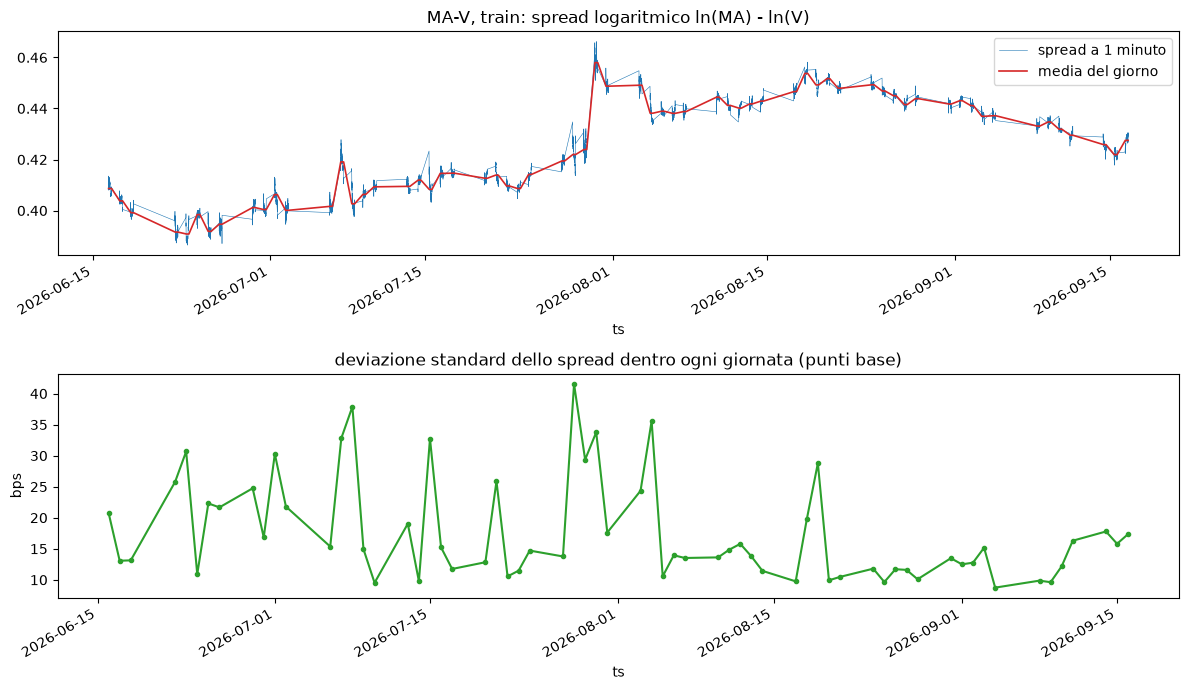

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
S[is_train].plot(ax=ax[0], lw=0.4, color="tab:blue", label="spread a 1 minuto")
(daily_mean.reindex(S[is_train].index.normalize()).set_axis(S[is_train].index)).plot(ax=ax[0], color="tab:red", lw=1.2, label="media del giorno")
ax[0].set_title("MA-V, train: spread logaritmico ln(MA) - ln(V)"); ax[0].legend()
daily_std.mul(1e4).plot(ax=ax[1], marker="o", ms=3, color="tab:green")
ax[1].set_title("deviazione standard dello spread dentro ogni giornata (punti base)"); ax[1].set_ylabel("bps")
plt.tight_layout(); plt.show()

**Lettura.**
- **β stimato = circa 1.4**, non 1: nel train MA si è mossa di più di V. Con β = 1 lo spread non passa il test ADF (p-value alto): su 64 giorni non possiamo escludere che si comporti come una camminata casuale. Il test di Engle-Granger (che stima β dai dati) dà un p-value di circa 0.03, sotto 0.05 ma non di molto: cointegrazione debole, e β è stato scelto *guardando gli stessi dati*, quindi il test va letto con prudenza.
- **L'emivita del rientro è di circa 5 giorni di seduta**: lo spread torna verso la sua media in modo *lento*, non nell'arco di una giornata. Il grafico mostra che il livello dello spread **deriva da un giorno all'altro** (linea rossa; la deviazione standard delle medie giornaliere è circa 190 punti base) molto più di quanto si muova dentro la giornata (la deviazione standard intraday è circa 18 punti base).
- **Conseguenza per la strategia.** Nel Passaggio 1 la coppia era stata scelta sui dati giornalieri (cointegrazione, emivita). Qui, sull'orizzonte di una giornata, il rientro non è garantito. Le oscillazioni dentro il giorno sono piccole (decine di punti base), quindi **i costi di trading peseranno molto** (Passaggio 6).
- **[SCELTA] Teniamo β = 1** perché coerente con importi uguali sulle gambe. **[APERTO]** Se l'intera strategia risultasse poco convincente, un'alternativa è β stimato con importi non uguali: richiede di cambiare la regola sugli importi, quindi va decisa insieme.

## 4. Lo z-score

Lo z-score misura quanto lo spread è lontano dal suo valore normale, in unità di variabilità:

$$z_t = \frac{S_t - \mathrm{EMA}(S)_t}{\sigma_t}$$

dove la media e la deviazione standard sono **esponenziali (EMA)**: le barre recenti pesano di più. Il parametro che regola la memoria è l'**emivita** (*halflife*): dopo `hl` barre il peso di un dato si è dimezzato. Emivita corta = z-score che segue lo spread da vicino (poche occasioni, di durata breve); emivita lunga = media più stabile (più occasioni quando lo spread si sposta).

**Due modi di calcolare la EMA** (la decisione nostra era la continua, e qui li mettiamo a confronto):

| | EMA **continua** [SCELTA] | EMA **azzerata ogni giorno** [confronto, parte 8] |
|---|---|---|
| Come | una sola EMA su tutta la serie, giorno dopo giorno | la EMA riparte da zero ogni mattina |
| Storia usata | anche i giorni prima | solo la giornata in corso |
| Il gap della notte | resta nello z-score: la mattina lo spread può essere lontano dalla media di ieri e lo z-score è subito alto | sparisce: all'apertura non c'è ancora una media |
| Inizio giornata | z-score disponibile da subito | servono 30 barre per partire |
| Rischio | il segnale del mattino può essere in realtà "il gap della notte tornerà indietro", cioè un'altra strategia | meno barre di storia, z-score più rumoroso |

Nella EMA continua la notte conta **come una barra sola**: la EMA non sa che tra le 16:00 e le 9:30 sono passate 17 ore e mezza.

**Niente lookahead.** Lo z-score della barra *t* usa solo dati fino alla chiusura di *t*. Lo verifichiamo calcolando lo z-score su una serie troncata e controllando che per le barre in comune i valori siano uguali.

In [5]:
def zscore(S, hl, reset_daily=False):
    # Z-score di S con media e deviazione standard esponenziali. hl = emivita in barre da 1 minuto.
    # reset_daily=False: EMA continua su tutta la serie (nostra scelta). reset_daily=True: la EMA riparte ogni mattina (confronto).
    if reset_daily:
        g = S.groupby(S.index.normalize())
        mean = g.transform(lambda x: x.ewm(halflife=hl, min_periods=30).mean())
        std = g.transform(lambda x: x.ewm(halflife=hl, min_periods=30).std())
    else:
        mean = S.ewm(halflife=hl, min_periods=EMA_MIN_PERIODS).mean()
        std = S.ewm(halflife=hl, min_periods=EMA_MIN_PERIODS).std()
    return ((S - mean) / std).to_numpy()

# controllo no-lookahead: lo z-score calcolato su una serie troncata coincide con quello della serie intera
for reset in (False, True):
    z_full = zscore(S, 60, reset)
    n_cut = 20000
    z_cut = zscore(S.iloc[:n_cut], 60, reset)
    assert np.allclose(z_cut, z_full[:n_cut], equal_nan=True), "lo z-score usa dati futuri!"
print("OK: lo z-score di ogni barra non dipende dalle barre successive (EMA continua e con azzeramento)")

OK: lo z-score di ogni barra non dipende dalle barre successive (EMA continua e con azzeramento)


## 5. Le regole di ingresso e di uscita

Il programma propone regole "tutte da testare". Ecco come le abbiamo scritte, una per una.

**Ingresso.** Alla chiusura della barra *t*, se lo z-score è oltre la soglia:
- $z_t > +\text{soglia}$ → spread troppo alto → **short MA, long V**;
- $z_t < -\text{soglia}$ → spread troppo basso → **long MA, short V**.

**Esecuzione alla barra successiva (niente lookahead).** Il segnale si calcola con i dati fino alla chiusura di *t*; l'ordine si esegue al **prezzo di apertura della barra *t+1***. Eseguire sulla stessa barra sarebbe lookahead (Lezione 2).

**Condizioni per aprire un trade** (tutte insieme):
1. $|z_t| \ge$ soglia di ingresso, e lo z-score esiste (dopo il periodo iniziale di avvio della EMA);
2. siamo almeno `OPEN_SKIP` = 15 minuti dopo l'apertura e almeno `CLOSE_SKIP` = 30 minuti prima della chiusura;
3. non c'è già un trade aperto sulla coppia (una posizione alla volta);
4. **nessuna delle due gambe ha la barra *t* riempita** (decisione B del Passaggio 2, opzione 2). Se per esempio MA non ha scambiato nel minuto, il suo prezzo è vecchio: lo spread si può essere allargato solo perché una gamba era ferma, e comprare o vendere a quel prezzo non è nemmeno possibile. Si conta quante occasioni vengono scartate per questo motivo. *Non* si guarda se la barra *t+1* è riempita: sarebbe usare un'informazione che al momento della decisione non esiste. Si conta però, come limite, quante volte il prezzo di esecuzione è vecchio.

**Uscita** (la prima che si verifica; il segnale di uscita si calcola alla chiusura della barra *k*, e l'ordine si esegue all'apertura di *k+1*):
- **rientro**: lo z-score torna entro la soglia di uscita (vicino a 0);
- **stop-loss**: lo z-score peggiora oltre soglia di ingresso + `STOP_EXTRA` (nel file Week 4 mancava ed era una debolezza);
- **tempo**: dopo `MAX_HOLD` = 90 minuti;
- **fine giornata**: all'ultima barra si chiude tutto al prezzo di chiusura. Nessuna posizione passa la notte.

Dopo un'uscita si lascia passare una barra prima di valutare un nuovo ingresso.

**Guadagno lordo del trade (per capire se il segnale ha senso, senza costi).** Con importi uguali sulle due gambe, il guadagno in punti base (1 bp = 0.01%) sull'importo di una gamba è la variazione dello spread, col segno della posizione:

$$\text{lordo (bps)} = \text{direzione} \times (S_{uscita} - S_{ingresso}) \times 10000, \qquad \text{direzione} = -\mathrm{sign}(z_{ingresso})$$

con $S$ calcolato sui prezzi di esecuzione. **È un guadagno lordo, senza costi di trading e senza impatto sul mercato**: i costi entrano nel Passaggio 6. Lo usiamo solo come misura per confrontare i parametri e per sapere se c'è del segnale.

**Colonne informative per il Passaggio 5.** Per ogni segnale si salvano anche i rendimenti di MA e V nell'ultima mezz'ora e quale dei due si è mosso di più (`leg_piu_mosso`). È una descrizione, non una regola di trading: l'agente di notizie avrà bisogno di sapere "su quale titolo guardare".

In [6]:
# Array usati dal motore dei segnali (calcolati una volta sola)
n = len(ts)
day_id = pd.factorize(day)[0]
minute = (ts.hour * 60 + ts.minute - (9 * 60 + 30)).to_numpy()                 # 0 = barra delle 09:30, 389 = barra delle 15:59
last_of_day = np.r_[day_id[1:] != day_id[:-1], True]
first_of_day = np.r_[True, day_id[1:] != day_id[:-1]]
day_start = np.maximum.accumulate(np.where(first_of_day, np.arange(n), 0))     # indice della prima barra della giornata di ogni barra
oA, oB, cA, cB = open_[A].to_numpy(), open_[B].to_numpy(), close[A].to_numpy(), close[B].to_numpy()
stale = (filled[A] | filled[B]).to_numpy()                                     # True se almeno una delle due gambe ha la barra riempita
train_arr = is_train


def run_rules(z, entry, exit_, stop=None, active=train_arr):
    # Applica le regole alla serie di z-score, barra per barra, in ordine cronologico.
    # Restituisce (elenco dei trade, numero di barre candidate scartate perché una gamba era riempita).
    stop = entry + STOP_EXTRA if stop is None else stop
    trades, blocked, i = [], 0, 0
    while i < n - 1:
        if not active[i]:
            i += 1
            continue
        candidate = (not np.isnan(z[i])) and abs(z[i]) >= entry and OPEN_SKIP <= minute[i] <= N_MINUTES - 1 - CLOSE_SKIP
        if not candidate:
            i += 1
            continue
        if stale[i]:                       # regola 4: una gamba ha il prezzo vecchio, non si apre
            blocked += 1
            i += 1
            continue
        side = np.sign(z[i])               # +1: spread alto (short MA, long V); -1: spread basso (long MA, short V)
        e = i + 1                          # esecuzione alla barra successiva
        s_in = np.log(oA[e] / oB[e])
        k = e
        while True:
            reason = None
            if last_of_day[k]:
                reason, a_out, b_out = "fine_giornata", cA[k], cB[k]
                break
            zk = side * z[k]
            if zk <= exit_: reason = "rientro"
            elif zk >= stop: reason = "stop"
            elif k - e + 1 >= MAX_HOLD: reason = "tempo"
            if reason:
                k += 1                     # l'uscita si esegue all'apertura della barra successiva
                a_out, b_out = oA[k], oB[k]
                break
            k += 1
        s_out = np.log(a_out / b_out)
        start = max(i - LOOKBACK + 1, day_start[i])
        trades.append(dict(
            t_signal=ts[i], t_entry=ts[e], t_exit=ts[k], side=-int(side), z_signal=z[i], exit_reason=reason,
            price_MA_in=oA[e], price_V_in=oB[e], price_MA_out=a_out, price_V_out=b_out, exec_price_stale=bool(stale[e]),
            ret_MA_30m=np.log(cA[i] / oA[start]), ret_V_30m=np.log(cB[i] / oB[start]),
            gross_bps=-side * (s_out - s_in) * 1e4,
        ))
        i = k + 1
    out = pd.DataFrame(trades)
    if len(out):
        out["leg_piu_mosso"] = np.where(out.ret_MA_30m.abs() >= out.ret_V_30m.abs(), "MA", "V")
        out["direction"] = np.where(out.side > 0, "long MA / short V", "short MA / long V")
        out["minutes_in_trade"] = (out.t_exit - out.t_entry).dt.total_seconds() / 60
        out["minute_of_day"] = (out.t_entry.dt.hour * 60 + out.t_entry.dt.minute) - (9 * 60 + 30)
    return out, blocked


# prova: una combinazione, per vedere che cosa restituisce
z_test = zscore(S, 60)
t_demo, b_demo = run_rules(z_test, 2.0, 0.5)
assert (t_demo.t_entry > t_demo.t_signal).all() and (t_demo.t_exit > t_demo.t_entry).all(), "ordine degli orari sbagliato"
assert t_demo.t_exit.max() <= pd.Timestamp(cut_day) + pd.Timedelta(days=1), "un trade del train arriva nel test"
print(f"prova (emivita 60, ingresso 2.0, uscita 0.5): {len(t_demo)} trade nel train, {b_demo} barre candidate scartate per gamba riempita")
t_demo[["t_signal", "t_entry", "t_exit", "direction", "z_signal", "exit_reason", "gross_bps"]].head()

prova (emivita 60, ingresso 2.0, uscita 0.5): 79 trade nel train, 5 barre candidate scartate per gamba riempita


,t_signal,t_entry,t_exit,direction,z_signal,exit_reason,gross_bps
0,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:12:00,short MA / long V,2.073157,rientro,9.011458
1,2026-06-16 13:00:00,2026-06-16 13:01:00,2026-06-16 14:31:00,long MA / short V,-2.017803,tempo,-18.555871
2,2026-06-17 09:47:00,2026-06-17 09:48:00,2026-06-17 10:54:00,long MA / short V,-2.299961,rientro,-0.453945
3,2026-06-17 15:26:00,2026-06-17 15:27:00,2026-06-17 15:59:00,long MA / short V,-2.299378,fine_giornata,-12.179200
4,2026-06-18 09:45:00,2026-06-18 09:46:00,2026-06-18 10:15:00,long MA / short V,-2.122065,rientro,29.061376


**Lettura.** I controlli (`assert`) verificano che ogni ingresso venga *dopo* il suo segnale e ogni uscita dopo l'ingresso, e che nessun trade del train arrivi nel periodo di test. Se il codice venisse cambiato in modo da violare queste regole, il notebook si fermerebbe.

## 6. Prova dei parametri sul train e scelta

Parametri da scegliere: emivita della EMA, soglia di ingresso, soglia di uscita. Si provano tutte le combinazioni della griglia **solo sul train**: 4 × 4 × 2 = 32 combinazioni per ogni tipo di EMA.

**Regola di scelta, scritta *prima* di guardare i risultati.** Tra le combinazioni con almeno `MIN_TRADES` = 30 trade nel train, si prende quella con il **guadagno lordo medio per trade** più alto. Poi si controlla che le combinazioni *vicine* (emivita e soglia di ingresso di un passo diverse) abbiano anch'esse un guadagno medio positivo: se solo un valore esatto funziona, è un campanello d'allarme (Passaggio 7 del programma).

**Il rischio.** 32 combinazioni su 64 giorni significa che con la sola fortuna una di esse sembrerà buona (rischio dei test multipli, `Programma.md`). Per questo c'è il minimo di trade, il controllo dei vicini e, alla fine, il test.

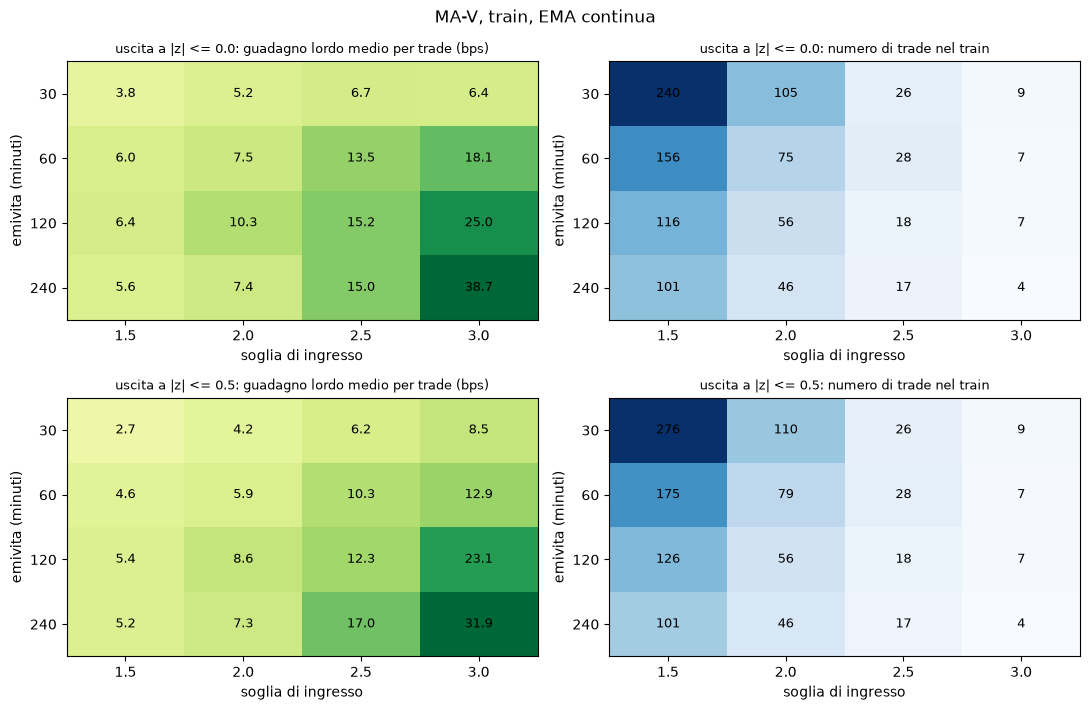

In [7]:
def run_grid(reset_daily):
    rows = []
    for hl in GRID_HL:
        z = zscore(S, hl, reset_daily)
        for entry in GRID_ENTRY:
            for exit_ in GRID_EXIT:
                t, blocked = run_rules(z, entry, exit_)
                rows.append(dict(hl=hl, entry=entry, exit=exit_, n_trades=len(t), blocked=blocked,
                                 mean_bps=t.gross_bps.mean() if len(t) else np.nan, win_rate=(t.gross_bps > 0).mean() if len(t) else np.nan,
                                 median_bps=t.gross_bps.median() if len(t) else np.nan))
    return pd.DataFrame(rows)

grid_cont = run_grid(reset_daily=False)

def show_grid(grid, title):
    fig, ax = plt.subplots(len(GRID_EXIT), 2, figsize=(11, 3.6 * len(GRID_EXIT)))
    for r, ex in enumerate(GRID_EXIT):
        g = grid[grid.exit == ex]
        for c, (col, name, cmap) in enumerate([("mean_bps", "guadagno lordo medio per trade (bps)", "RdYlGn"), ("n_trades", "numero di trade nel train", "Blues")]):
            p = g.pivot(index="hl", columns="entry", values=col)
            im = ax[r, c].imshow(p.values, cmap=cmap, aspect="auto", vmin=(-30 if col == "mean_bps" else None), vmax=(30 if col == "mean_bps" else None))
            ax[r, c].set_xticks(range(len(p.columns)), p.columns); ax[r, c].set_yticks(range(len(p.index)), p.index)
            ax[r, c].set_xlabel("soglia di ingresso"); ax[r, c].set_ylabel("emivita (minuti)"); ax[r, c].set_title(f"uscita a |z| <= {ex}: {name}", fontsize=9)
            for (y, x), v in np.ndenumerate(p.values):
                ax[r, c].text(x, y, "-" if np.isnan(v) else f"{v:.0f}" if col == "n_trades" else f"{v:.1f}", ha="center", va="center", fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_grid(grid_cont, "MA-V, train, EMA continua")

In [8]:
def choose(grid):
    # regola dichiarata: tra le combinazioni con almeno MIN_TRADES trade, guadagno lordo medio più alto
    ok = grid[grid.n_trades >= MIN_TRADES]
    best = ok.sort_values("mean_bps", ascending=False).iloc[0]
    # controllo dei vicini: emivita e soglia di ingresso di un passo (stessa soglia di uscita)
    i_hl, i_en = GRID_HL.index(best.hl), GRID_ENTRY.index(best.entry)
    neigh = [(GRID_HL[a], GRID_ENTRY[b]) for a in range(max(0, i_hl - 1), min(len(GRID_HL), i_hl + 2))
             for b in range(max(0, i_en - 1), min(len(GRID_ENTRY), i_en + 2)) if (a, b) != (i_hl, i_en)]
    nb = grid[(grid.exit == best.exit) & pd.Series(list(zip(grid.hl, grid.entry)), index=grid.index).isin(neigh)]
    return best, nb

best, neighbours = choose(grid_cont)
print(f"combinazioni con almeno {MIN_TRADES} trade: {(grid_cont.n_trades >= MIN_TRADES).sum()} su {len(grid_cont)}")
print(f"SCELTA -> emivita {best.hl:.0f}, ingresso {best.entry}, uscita {best.exit}:  {best.n_trades:.0f} trade, lordo medio {best.mean_bps:.1f} bps, quota di trade in positivo {best.win_rate:.0%}")
print(f"combinazioni vicine: {len(neighbours)}, di cui con guadagno medio positivo: {(neighbours.mean_bps > 0).sum()}; guadagno medio delle vicine {neighbours.mean_bps.mean():.1f} bps")
grid_cont.sort_values("mean_bps", ascending=False).head(8).round(2)

combinazioni con almeno 30 trade: 16 su 32
SCELTA -> emivita 120, ingresso 2.0, uscita 0.0:  56 trade, lordo medio 10.3 bps, quota di trade in positivo 68%
combinazioni vicine: 8, di cui con guadagno medio positivo: 8; guadagno medio delle vicine 9.6 bps


,hl,entry,exit,n_trades,blocked,mean_bps,win_rate,median_bps
30,240,3.0,0.0,4,0,38.73,0.75,55.57
31,240,3.0,0.5,4,0,31.91,0.75,52.68
22,120,3.0,0.0,7,0,25.01,0.86,29.48
23,120,3.0,0.5,7,0,23.08,0.86,23.19
14,60,3.0,0.0,7,0,18.11,0.86,19.91
29,240,2.5,0.5,17,0,17.02,0.82,22.69
20,120,2.5,0.0,18,0,15.16,0.78,19.61
28,240,2.5,0.0,17,0,15.02,0.82,14.08


**Lettura.** (Il commento sui numeri è nel riquadro di conclusione della parte 10: qui si guarda la mappa. Verde = guadagno lordo medio positivo, rosso = negativo; il secondo grafico mostra *quanti* trade ci sono dietro ogni cella.) Due cose da notare sempre:
- più la soglia di ingresso è alta, meno trade ci sono: celle con pochissimi trade danno medie molto instabili, anche se il colore è un verde intenso;
- il guadagno è **lordo**: va confrontato con i costi (Passaggio 6), che per ogni trade pesano su 4 operazioni.

## 7. I segnali con i parametri scelti: diagnostica

Si bloccano i parametri scelti nella parte 6 e si guardano i segnali nel dettaglio. L'obiettivo non è dire "funziona", ma **capire da dove viene il guadagno** e quanti trade ci sono, perché con pochi trade nessuna metrica è affidabile.

In [9]:
HL, ENTRY, EXIT = int(best.hl), float(best.entry), float(best.exit)
z_cont = zscore(S, HL)
trades, blocked = run_rules(z_cont, ENTRY, EXIT)

n_cand = trades.shape[0] + blocked
print(f"Parametri bloccati: emivita {HL} minuti, ingresso |z| >= {ENTRY}, uscita |z| <= {EXIT}, stop |z| >= {ENTRY + STOP_EXTRA}, tempo massimo {MAX_HOLD} minuti")
print(f"trade nel train: {len(trades)}   (in media {len(trades) / N_TRAIN_DAYS:.2f} al giorno, su {trades.t_entry.dt.normalize().nunique()} giorni diversi)")
print(f"barre candidate scartate perché una gamba era riempita: {blocked}  (conto per barre, non per episodi)")
print(f"trade con prezzo di esecuzione vecchio (barra t+1 riempita): {trades.exec_price_stale.sum()} su {len(trades)}")
print(f"guadagno lordo medio {trades.gross_bps.mean():.1f} bps, mediano {trades.gross_bps.median():.1f}, quota in positivo {(trades.gross_bps > 0).mean():.0%}, somma {trades.gross_bps.sum():.0f} bps")
print(f"errore standard del guadagno medio: {trades.gross_bps.std() / np.sqrt(len(trades)):.1f} bps  (il guadagno medio è 'affidabile' solo se molto più grande di questo)")
print("\nMotivo di uscita:"); print(trades.groupby("exit_reason").gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"}))
print("\nPer fascia oraria dell'ingresso (minuti dall'apertura):")
trades["fascia"] = pd.cut(trades.minute_of_day, [0, 30, 60, 120, 240, 390], right=True, labels=["15-30", "30-60", "60-120", "120-240", "240-390"], include_lowest=True)
print(trades.groupby("fascia", observed=False).gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"}))

Parametri bloccati: emivita 120 minuti, ingresso |z| >= 2.0, uscita |z| <= 0.0, stop |z| >= 3.5, tempo massimo 90 minuti
trade nel train: 56   (in media 0.88 al giorno, su 46 giorni diversi)
barre candidate scartate perché una gamba era riempita: 2  (conto per barre, non per episodi)
trade con prezzo di esecuzione vecchio (barra t+1 riempita): 2 su 56
guadagno lordo medio 10.3 bps, mediano 9.3, quota in positivo 68%, somma 578 bps
errore standard del guadagno medio: 3.2 bps  (il guadagno medio è 'affidabile' solo se molto più grande di questo)

Motivo di uscita:
               trade  lordo medio (bps)
exit_reason                            
fine_giornata      4               21.3
rientro           20               28.2
stop               1              -12.9
tempo             31               -1.9

Per fascia oraria dell'ingresso (minuti dall'apertura):
         trade  lordo medio (bps)
fascia                           
15-30       29               10.7
30-60        3               24.

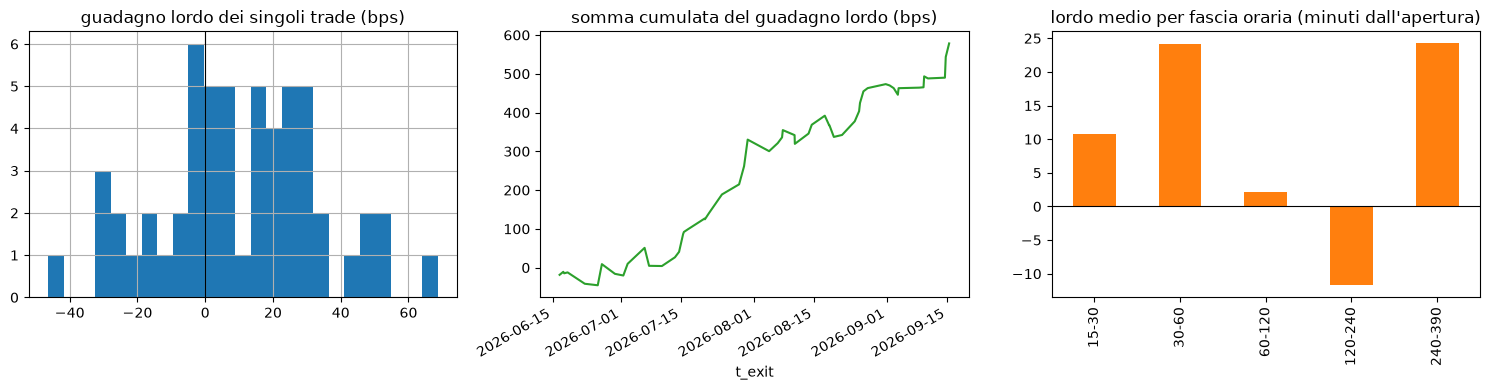

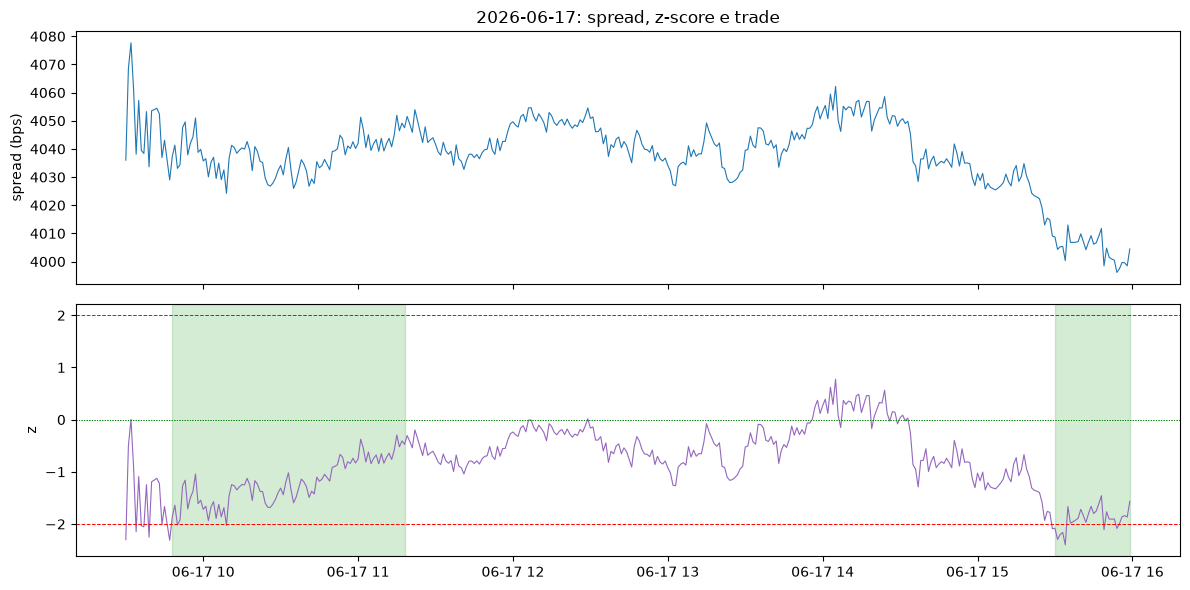

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
trades.gross_bps.hist(bins=25, ax=ax[0], color="tab:blue"); ax[0].axvline(0, color="k", lw=0.8); ax[0].set_title("guadagno lordo dei singoli trade (bps)")
trades.set_index("t_exit").gross_bps.cumsum().plot(ax=ax[1], color="tab:green"); ax[1].set_title("somma cumulata del guadagno lordo (bps)")
trades.groupby("fascia", observed=False).gross_bps.mean().plot.bar(ax=ax[2], color="tab:orange"); ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_title("lordo medio per fascia oraria (minuti dall'apertura)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

# un esempio: la giornata del train con più trade
d_ex = trades.t_entry.dt.normalize().value_counts().index[0]
m = (day == d_ex)
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(ts[m], S[m] * 1e4, lw=0.8); ax[0].set_ylabel("spread (bps)"); ax[0].set_title(f"{d_ex.date()}: spread, z-score e trade")
ax[1].plot(ts[m], z_cont[m], lw=0.8, color="tab:purple")
for lvl in (ENTRY, -ENTRY): ax[1].axhline(lvl, color="r", ls="--", lw=0.7)
for lvl in (EXIT, -EXIT): ax[1].axhline(lvl, color="g", ls=":", lw=0.7)
tt = trades[trades.t_entry.dt.normalize() == d_ex]
for _, r in tt.iterrows():
    ax[1].axvspan(r.t_entry, r.t_exit, color=("tab:red" if r.side < 0 else "tab:green"), alpha=0.2)
ax[1].set_ylabel("z"); plt.tight_layout(); plt.show()

**Lettura.** Nel grafico dell'esempio le fasce colorate sono i trade (rosso: short MA / long V; verde: long MA / short V). Le righe tratteggiate rosse sono le soglie di ingresso, quelle punteggiate verdi le soglie di uscita. Nella tabella per fascia oraria si vede **dove** nasce il guadagno: è la tabella più importante di questa parte (vedi parte 10).

## 8. Confronto: EMA azzerata ogni giorno

La stessa griglia, con la stessa regola di scelta, ma con la EMA che riparte da zero ogni mattina. Serve a capire quanto il risultato dipenda dalla scelta della EMA continua. **Non è una scelta alternativa che adottiamo**: è un controllo.

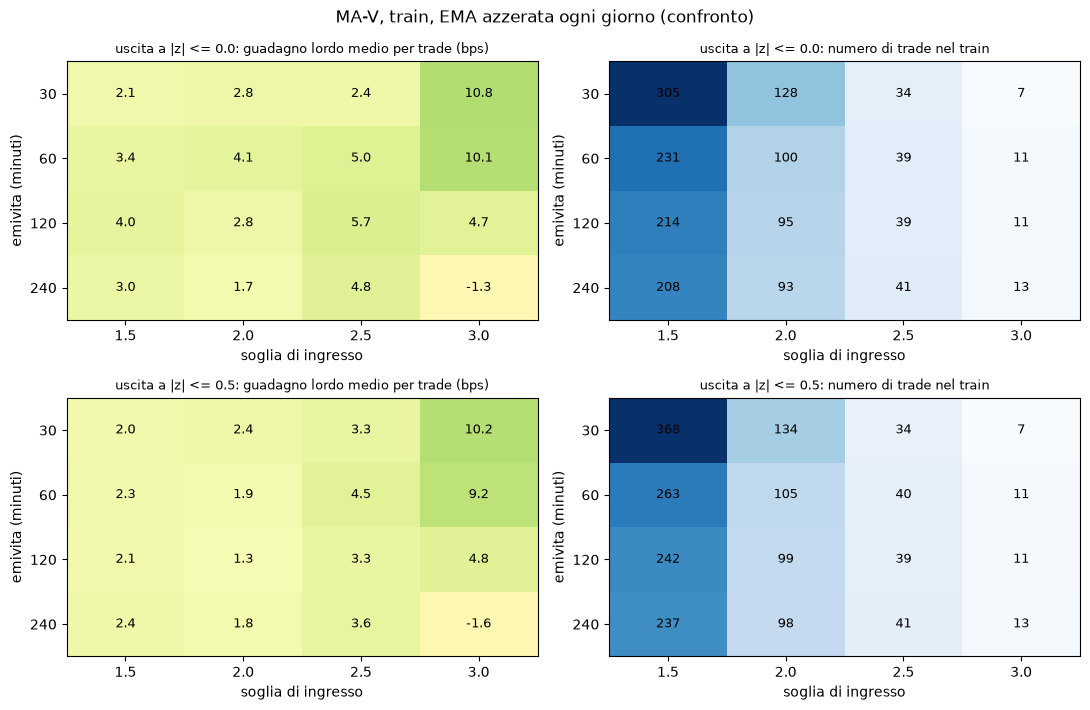

Con la stessa regola di scelta -> emivita 120, ingresso 2.5, uscita 0.0:  39 trade, lordo medio 5.7 bps
combinazioni vicine con guadagno medio positivo: 7 su 8


,EMA continua,EMA azzerata
combinazioni con >= 30 trade,16.0,24.0
"lordo medio (bps), media delle combinazioni",6.0,3.0
lordo medio massimo,10.3,5.7


In [11]:
grid_reset = run_grid(reset_daily=True)
show_grid(grid_reset, "MA-V, train, EMA azzerata ogni giorno (confronto)")

best_r, neigh_r = choose(grid_reset) if (grid_reset.n_trades >= MIN_TRADES).any() else (None, None)
if best_r is not None:
    print(f"Con la stessa regola di scelta -> emivita {best_r.hl:.0f}, ingresso {best_r.entry}, uscita {best_r.exit}:  {best_r.n_trades:.0f} trade, lordo medio {best_r.mean_bps:.1f} bps")
    print(f"combinazioni vicine con guadagno medio positivo: {(neigh_r.mean_bps > 0).sum()} su {len(neigh_r)}")
cmp = pd.DataFrame({
    "EMA continua": grid_cont.assign(ok=grid_cont.n_trades >= MIN_TRADES).query("ok").mean_bps.describe()[["count", "mean", "max"]],
    "EMA azzerata": grid_reset.assign(ok=grid_reset.n_trades >= MIN_TRADES).query("ok").mean_bps.describe()[["count", "mean", "max"]],
}).rename(index={"count": "combinazioni con >= 30 trade", "mean": "lordo medio (bps), media delle combinazioni", "max": "lordo medio massimo"}).round(1)
cmp

**Lettura.** Nel confronto contano due numeri: quante combinazioni superano il minimo di 30 trade e quanto vale il guadagno medio. Il commento sui risultati è nella parte 10.

## 9. Salvataggio dei segnali del train

Si salva la tabella dei segnali con i parametri bloccati: è l'input del Passaggio 5 (agente di notizie), che riceve per ogni segnale coppia, titolo che si è mosso, orario e direzione. Il file è in `data/processed/` (cartella ignorata da git, come gli altri dati: chi lo vuole rilancia il notebook).

Colonne: orari del segnale, dell'ingresso e dell'uscita (ora di New York); `direction`; `z_signal`; prezzi di MA e V all'ingresso e all'uscita; `exit_reason`; `gross_bps` (lordo, senza costi); `leg_piu_mosso` e i rendimenti degli ultimi 30 minuti; `exec_price_stale` (prezzo di esecuzione vecchio); i parametri usati.

In [12]:
out = trades.copy()
out.insert(0, "pair", PAIR)
out["ema"] = "continua"
out["hl_min"], out["entry_z"], out["exit_z"], out["stop_z"] = HL, ENTRY, EXIT, ENTRY + STOP_EXTRA
cols = ["pair", "t_signal", "t_entry", "t_exit", "direction", "z_signal", "leg_piu_mosso", "ret_MA_30m", "ret_V_30m",
        "price_MA_in", "price_V_in", "price_MA_out", "price_V_out", "exit_reason", "gross_bps", "minutes_in_trade", "exec_price_stale",
        "ema", "hl_min", "entry_z", "exit_z", "stop_z"]
OUT_SIGNALS.parent.mkdir(parents=True, exist_ok=True)
out[cols].to_csv(OUT_SIGNALS, index=False)
assert out.t_exit.max() < pd.Timestamp(cut_day) + pd.Timedelta(days=1), "il file dei segnali contiene giorni di test"
print(f"salvati {len(out)} segnali in {OUT_SIGNALS}  (ultimo giorno: {out.t_exit.max().date()}, taglio del train: {cut_day.date()})")
out[cols].head()

salvati 56 segnali in ../data/processed/signals_MA-V_train.csv  (ultimo giorno: 2026-09-15, taglio del train: 2026-09-16)


,pair,t_signal,t_entry,t_exit,direction,z_signal,leg_piu_mosso,ret_MA_30m,ret_V_30m,price_MA_in,...,price_V_out,exit_reason,gross_bps,minutes_in_trade,exec_price_stale,ema,hl_min,entry_z,exit_z,stop_z
0,MA-V,2026-06-16 13:00:00,2026-06-16 13:01:00,2026-06-16 14:31:00,long MA / short V,-2.023089,V,0.000501,0.003651,499.14,...,332.480,tempo,-18.555871,90.0,False,continua,120,2.0,0.0,3.5
1,MA-V,2026-06-17 09:47:00,2026-06-17 09:48:00,2026-06-17 11:18:00,long MA / short V,-2.310840,V,-0.001871,0.005199,502.50,...,334.025,tempo,7.776505,90.0,False,continua,120,2.0,0.0,3.5
2,MA-V,2026-06-17 15:29:00,2026-06-17 15:30:00,2026-06-17 15:59:00,long MA / short V,-2.091849,MA,-0.005961,-0.003836,493.31,...,330.380,fine_giornata,-3.855320,29.0,False,continua,120,2.0,0.0,3.5
3,MA-V,2026-06-18 09:45:00,2026-06-18 09:46:00,2026-06-18 11:16:00,long MA / short V,-2.423061,MA,-0.007751,-0.006767,490.71,...,329.310,tempo,2.341830,90.0,False,continua,120,2.0,0.0,3.5
4,MA-V,2026-06-22 09:57:00,2026-06-22 09:58:00,2026-06-22 11:28:00,long MA / short V,-2.330374,V,0.008290,0.009499,492.94,...,328.820,tempo,-29.305011,90.0,False,continua,120,2.0,0.0,3.5


## 10. Cosa abbiamo trovato, limiti, cosa resta aperto

I numeri sotto sono quelli dell'esecuzione di questo notebook sul train (16 giugno - 16 settembre 2026). Se si cambia un parametro e si rilancia, vanno riaggiornati.

### Parametri scelti (EMA continua, β = 1)
Emivita 120 minuti, ingresso a $|z| \ge 2.0$, uscita a $|z| \le 0$, stop a $|z| \ge 3.5$, tempo massimo 90 minuti, nessun ingresso nei primi 15 e negli ultimi 30 minuti.

### Risultati sul train
| | |
|---|---|
| Trade nel train | **56** (0.9 al giorno, in 46 giorni su 64) |
| Guadagno lordo medio per trade | **10.3 bps** (mediano 9.3; errore standard 3.2 bps; 68% dei trade in positivo) |
| Combinazioni vicine nella griglia | 8 su 8 con guadagno medio positivo (media 9.6 bps) |
| Barre candidate scartate perché una gamba era riempita | 2 (e solo 2 trade su 56 eseguiti con prezzo vecchio) |

**Come escono i trade.**

| Uscita | Trade | Lordo medio |
|---|---|---|
| Rientro (z torna a 0) | 20 | +28.2 bps |
| Fine giornata | 4 | +21.3 bps |
| Tempo (90 minuti senza rientro) | 31 | -1.9 bps |
| Stop-loss | 1 | -12.9 bps |

### Cosa ci dicono
1. **Lo spread di MA-V rientra lentamente.** L'emivita è di circa 5 giorni di seduta, e il livello dello spread cambia da un giorno all'altro di circa 190 punti base, contro circa 18 di oscillazione dentro la giornata. Coerente con questo, **solo 20 trade su 56 (36%) rientrano entro 90 minuti**; gli altri 31 escono per tempo con un guadagno vicino a zero. Il guadagno medio viene quasi tutto dai trade che rientrano. Attenzione: i trade che rientrano escono prima, quindi la media di quel gruppo è alta *per costruzione* (usciamo appena rientrano). Contano il numero totale e il guadagno medio complessivo, non quello dei sottogruppi.
2. **Il segnale c'è ma è piccolo.** 10 bps lordi per trade, con errore standard di 3 bps: positivo (circa 3 errori standard) ma modesto. **Non abbiamo ancora i costi**: ogni trade ha 4 operazioni (Passaggio 6). Su 10 bps il margine per i costi è stretto, e non possiamo dire ora se il guadagno netto sarà positivo.
3. **Metà dei trade nasce subito dopo il periodo di attesa dell'apertura** (29 trade su 56 tra 15 e 30 minuti). Con la EMA continua, il gap della notte (MA e V che aprono in modo diverso rispetto a ieri sera) fa partire lo z-score già alto la mattina, e noi entriamo scommettendo che il gap rientri. Questi trade hanno guadagno medio (10.7 bps) simile al totale, quindi non spiegano da soli il risultato, ma è una strategia diversa dal "movimento anomalo dentro la giornata" descritto nel programma, e va dichiarato. **[APERTO]** Decidere se tenerli (sono una fonte vera di segnali) o escluderli alzando `OPEN_SKIP`. Nelle altre fasce orarie i trade sono 3, 11, 4 e 9: troppo pochi per dire qualcosa.
4. **EMA continua contro EMA azzerata ogni giorno** (parte 8). Con l'EMA azzerata il massimo è molto più basso: la migliore combinazione (emivita 120, ingresso 2.5, 39 trade) dà 5.7 bps contro 10.3, e il guadagno medio delle combinazioni con almeno 30 trade è circa 3 bps contro circa 6. La continua è migliore, ma in parte perché sfrutta il gap della notte (punto 3). L'azzerata ha più combinazioni utilizzabili (24 contro 16) perché genera più segnali.
5. **Dove la griglia è fuorviante.** Il guadagno medio cresce con la soglia di ingresso e con l'emivita, ma il massimo (emivita 240, ingresso 3.0: 38.7 bps) viene da **4 trade**. Per questo la regola di scelta chiede almeno 30 trade: la combinazione scelta è la migliore tra quelle con campione sufficiente.

### Limiti da dichiarare nel report
- **Pochi dati e un solo tipo di mercato**: 64 giorni di train, una sola coppia, giugno-settembre 2026.
- **Test multipli**: 32 combinazioni provate per ogni tipo di EMA. Con la sola fortuna una sembra buona; difese: minimo di 30 trade, controllo dei vicini e test finale.
- **L'errore standard di 3.2 bps assume trade indipendenti**: in realtà trade vicini nel tempo condividono lo stesso andamento del giorno, quindi l'incertezza vera è un po' maggiore.
- **Guadagni lordi**: niente costi, niente impatto sul prezzo, nessun problema di reperire titoli per lo short.
- **β = 1 e non stazionarietà**: su 64 giorni lo spread con β = 1 non supera il test ADF (p-value 0.44). La cointegrazione trovata nel Passaggio 1 sui dati giornalieri non è confermata con forza sull'intraday.
- **MA ha il 9.5% di minuti riempiti** nel train (V l'1.5%). Con la regola "non apro se una gamba è riempita" scartiamo pochissimo (2 barre), ma la regola non protegge dai prezzi vecchi alla barra di esecuzione (2 trade su 56).
- **Prezzi non aggiustati per i dividendi** (limite del Passaggio 2).

### Cosa resta aperto
1. **Test (32 giorni, dal 17 settembre al 30 ottobre).** Non è stato calcolato. Si usa una volta sola, con i parametri bloccati qui, e solo dopo aver deciso il resto (compreso il punto 3 sopra).
2. **Numero di segnali per il Passaggio 5.** 56 segnali nel train sono pochi per confrontare opzioni dell'agente. Abbassare l'ingresso a $|z| \ge 1.5$ dà circa 116 trade ma guadagno lordo medio più basso (6.4 bps): da decidere se vale la pena, tenendo conto che l'agente chiama un LLM per ogni segnale.
3. **Trigger secondario** del programma (un singolo titolo che si muove in modo anomalo): non implementato. La colonna `leg_piu_mosso` è solo descrittiva.
4. **Estensione alle altre 9 coppie**, solo dopo aver deciso i punti precedenti, con gli stessi parametri o con una scelta per coppia da fare sul train.
5. **Costi e backtest** (Passaggio 6) per sapere se i 10 bps lordi sopravvivono.
6. **`docs/Programma.md` non è stato aggiornato**: va aggiornata la sezione del Passaggio 4 con quanto fatto qui, da concordare nel gruppo.